# 📊 EDA: Mujeres en el sector tech en Europa

**Objetivo:** entender, limpiar y explorar datos sobre la presencia de mujeres en tech en Europa (con foco en perfiles junior) y contar la historia para alguien que no sabe de datos.

**Fuentes:** Eurostat (especialistas TIC por sexo/edad/educación) + Kaggle ML & DS Survey filtrada a Europa.

> ⚠️ Estos datos miden *representación*, no *contratación*.

## Preguntas de partida
1. ¿Qué % de especialistas TIC son mujeres en España frente a la UE, y cómo ha evolucionado desde 2004? *(Eurostat)*
2. ¿Los países con plantillas TIC más jóvenes tienen más mujeres? *(Eurostat, a nivel de país)*
3. ¿Qué % de las personas junior de la encuesta son mujeres, frente al total, en Europa? *(Kaggle)*
4. ¿Qué diferencias hay entre mujeres y hombres juniors en formación, rol y salario? *(Kaggle, con muestra pequeña)*
5. ¿Coincide el % de mujeres de la encuesta con el de Eurostat país por país? *(merge de ambas fuentes)*


## 1. Configuración e imports

In [1]:
import sys
from pathlib import Path

# Busca la carpeta raíz del proyecto (la que contiene "src") subiendo desde donde se ejecuta el notebook
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("No encuentro la carpeta 'src'. Abre el notebook dentro del proyecto completo.")
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import missingno as msno

from src.cleaning import (read_eurostat_tsv, eurostat_to_long, read_kaggle_survey,
                          normalize_gender, COUNTRY_TO_GEO)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RAW = str(ROOT / "data" / "raw") + "/"
PROCESSED = str(ROOT / "data" / "processed") + "/"
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /Users/nayeli/Documents/Bootcamp IA/EDA-nayeli


### Columnas de la encuesta de Kaggle (rellenar)
Los códigos (`Q2`, `Q3`…) cambian según la edición. **Abre el CSV y mira la 2ª fila (texto de cada pregunta)** para localizar cada columna, y rellena este diccionario:

In [2]:
COLS = {
    "age": "Q2",          # edad (rangos de texto)
    "gender": "Q3",       # género
    "country": "Q4",      # país de residencia
    "student": "Q5",      # ¿es estudiante actualmente?
    "education": "Q8",    # nivel educativo
    "experience": "Q11",  # años programando
    "role": "Q23",        # cargo actual (vacío en muchos casos)
    "company_size": "Q25",# tamaño de la empresa
    "salary": "Q29",      # salario anual aprox. en USD (rangos de texto)
}

## 2. Carga de datos

In [3]:
# --- Eurostat (TSV) ---
es_sex = read_eurostat_tsv(RAW + "isoc_sks_itsps.tsv")
es_age = read_eurostat_tsv(RAW + "isoc_sks_itspa.tsv")
es_edu = read_eurostat_tsv(RAW + "isoc_sks_itspe.tsv")

# --- Kaggle (CSV) ---
kg = read_kaggle_survey(RAW + "kaggle_survey_responses.csv")

## 3. Estructura inicial
`shape`, `info()`, `head()` y `describe()` de cada dataset.

In [4]:
for name, d in [("Eurostat sexo", es_sex), ("Eurostat edad", es_age), ("Eurostat educación", es_edu), ("Kaggle", kg)]:
    print(f"=== {name}: {d.shape[0]} filas x {d.shape[1]} columnas")
es_sex.head()

=== Eurostat sexo: 148 filas x 26 columnas
=== Eurostat edad: 148 filas x 26 columnas
=== Eurostat educación: 184 filas x 26 columnas
=== Kaggle: 23997 filas x 296 columnas


,freq,unit,sex,geo,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,A,PC,F,AT,22.1 be,20.0 be,19.7 e,20.9 be,17.6 e,18.8 e,19.1 e,13.2 b,16.8 e,14.2 e,13.4 e,14.3 e,17.1,15.7 e,18.4,20.4,20.3,19.0 b,19.3,19.5,21.1 e,19.7 e
1,A,PC,F,BA,:,:,:,:,:,:,:,:,:,:,:,:,:,:,:,:,:,17.8 bu,24.3 e,19.5 e,20.5 e,26.5 e
2,A,PC,F,BE,15.1 e,18.1 be,17.3 e,18.7 e,17.4 e,18.4 e,19.2 e,16.6 be,17.1,15.5,15.2,15.1,14.1,15.6 b,16.8,17.2 e,17.4,19.6 b,18.7,19.4,19.0,17.6
3,A,PC,F,BG,26.4 e,26.5 be,28.3 e,28.9 e,31.3 be,30.6 e,31.1 be,33.0 be,32.4 e,29.8 e,31.6 e,30.9 e,29.1 e,29.2 e,30.1 e,28.3 b,28.4,28.2 b,28.9,29.1,27.0 be,25.0
4,A,PC,F,CH,:,:,:,:,:,:,:,12.6 be,13.3 e,14.2 e,13.8 e,14.2,15.0,15.2,14.5,16.6 e,16.3 e,16.4 b,16.0,16.6,17.9,17.4 e


In [5]:
es_sex.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   freq    148 non-null    str  
 1   unit    148 non-null    str  
 2   sex     148 non-null    str  
 3   geo     148 non-null    str  
 4   2004    148 non-null    str  
 5   2005    148 non-null    str  
 6   2006    148 non-null    str  
 7   2007    148 non-null    str  
 8   2008    148 non-null    str  
 9   2009    148 non-null    str  
 10  2010    148 non-null    str  
 11  2011    148 non-null    str  
 12  2012    148 non-null    str  
 13  2013    148 non-null    str  
 14  2014    148 non-null    str  
 15  2015    148 non-null    str  
 16  2016    148 non-null    str  
 17  2017    148 non-null    str  
 18  2018    148 non-null    str  
 19  2019    148 non-null    str  
 20  2020    148 non-null    str  
 21  2021    148 non-null    str  
 22  2022    148 non-null    str  
 23  2023    148 non-null    st

In [6]:
kg.iloc[:, :12].head()

,Duration (in seconds),Q2,Q3,Q4,Q5,Q6_1,Q6_2,Q6_3,Q6_4,Q6_5,Q6_6,Q6_7
0,121,30-34,Man,India,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,462,30-34,Man,Algeria,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,293,18-21,Man,Egypt,Yes,Coursera,edX,NaN,DataCamp,NaN,Udacity,Udemy
3,851,55-59,Man,France,No,Coursera,NaN,Kaggle Learn Courses,NaN,NaN,NaN,Udemy
4,232,45-49,Man,India,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
kg.iloc[:, :12].describe(include='all').T.head(12)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Duration (in seconds),23997.0,NaN,NaN,NaN,10090.095845,111540.307468,120.0,264.0,414.0,715.0,2533678.0
Q2,23997,11,18-21,4559,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q3,23997,5,Man,18266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q4,23997,58,India,8792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q5,23997,2,No,12036,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q6_1,9699,1,Coursera,9699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q6_2,2474,1,edX,2474,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q6_3,6628,1,Kaggle Learn Courses,6628,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q6_4,3718,1,DataCamp,3718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q6_5,944,1,Fast.ai,944,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Calidad de los datos: nulos, duplicados y flags

In [8]:
print("Duplicados Eurostat (sexo):", es_sex.duplicated().sum())
print("Duplicados Kaggle:", kg.duplicated().sum())

nulos = (kg.isna().mean() * 100).sort_values(ascending=False)
print("Columnas Kaggle con >80% de nulos:", (nulos > 80).sum(), "de", len(nulos))
nulos.head(10)

Duplicados Eurostat (sexo): 0
Duplicados Kaggle: 1
Columnas Kaggle con >80% de nulos: 246 de 296


Q42_8     100.0
Q36_14    100.0
Q17_14    100.0
Q12_14    100.0
Q18_13    100.0
Q15_14    100.0
Q31_11    100.0
Q19_7     100.0
Q35_15    100.0
Q13_13    100.0
dtype: float64

**Qué buscar aquí (anota tus hallazgos):**
- En Eurostat, celdas con `:` (dato no disponible) y flags como `b` (ruptura de serie) o `u` (poco fiable).
- En Kaggle, muchas columnas casi vacías (preguntas de selección múltiple) y categorías de género poco frecuentes.

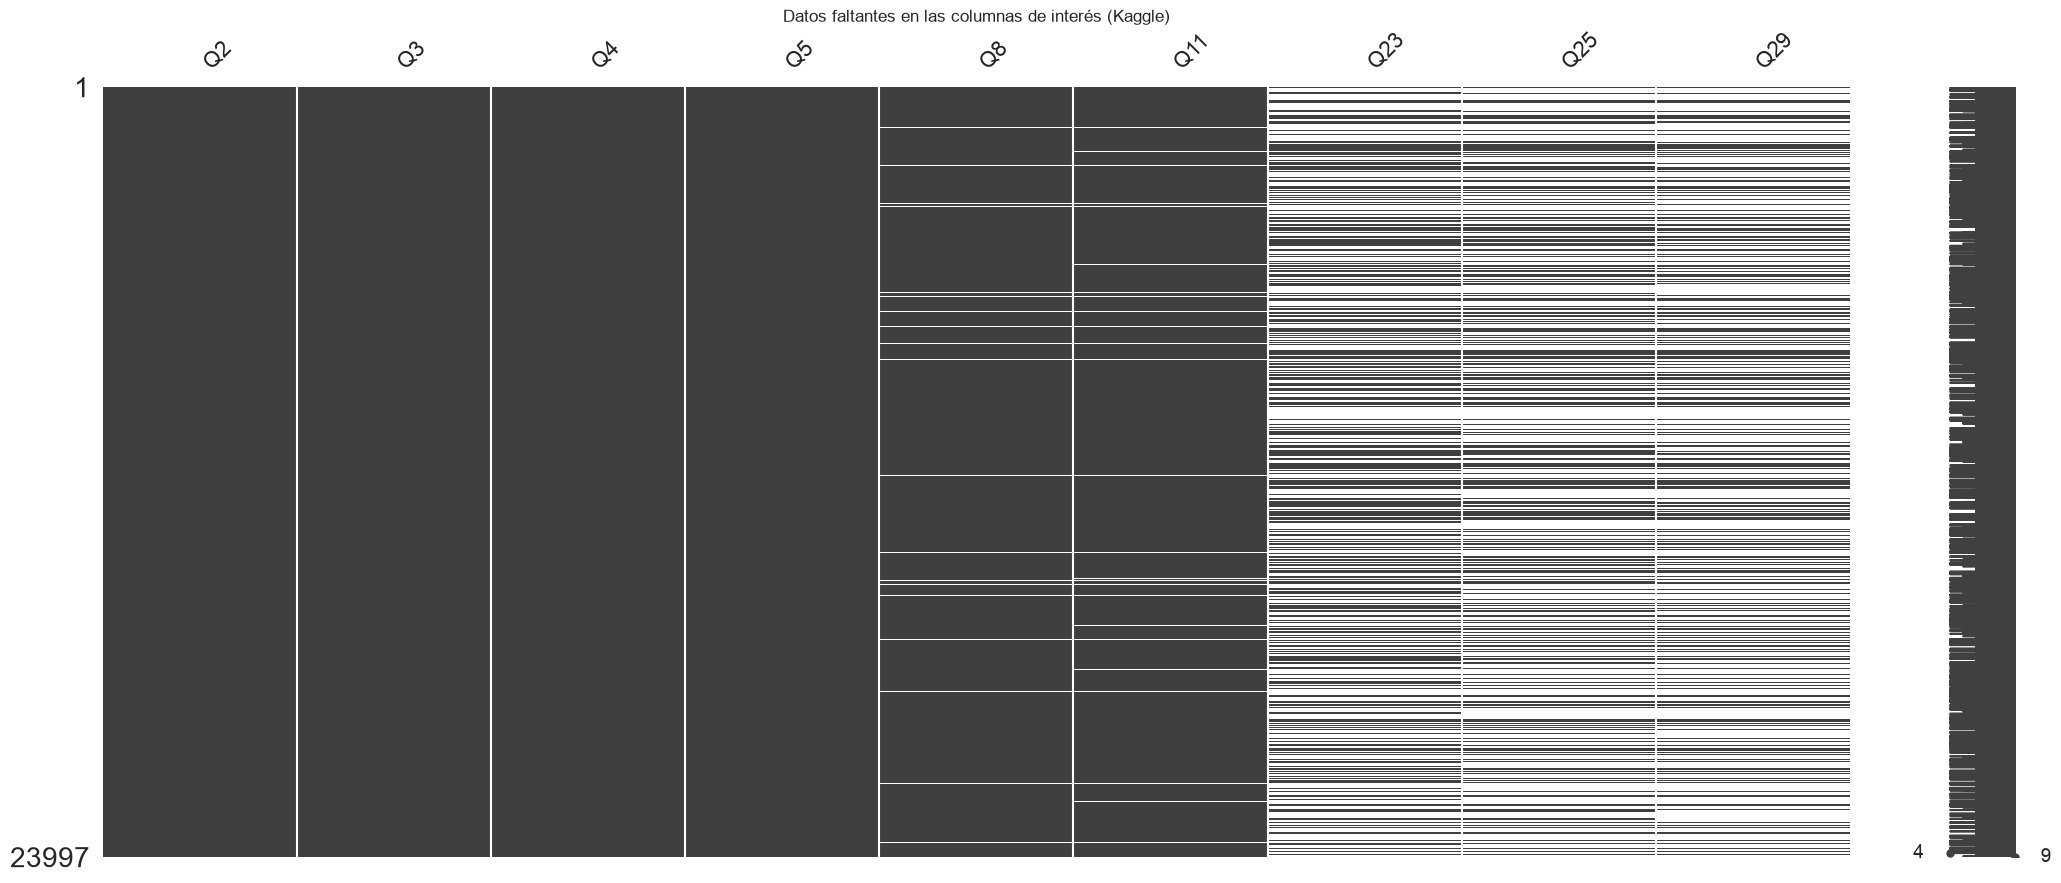

In [9]:
cols_interes = ["Q2", "Q3", "Q4", "Q5", "Q8", "Q11", "Q23", "Q25", "Q29"]

msno.matrix(kg[cols_interes])
plt.title("Datos faltantes en las columnas de interés (Kaggle)")
plt.show()

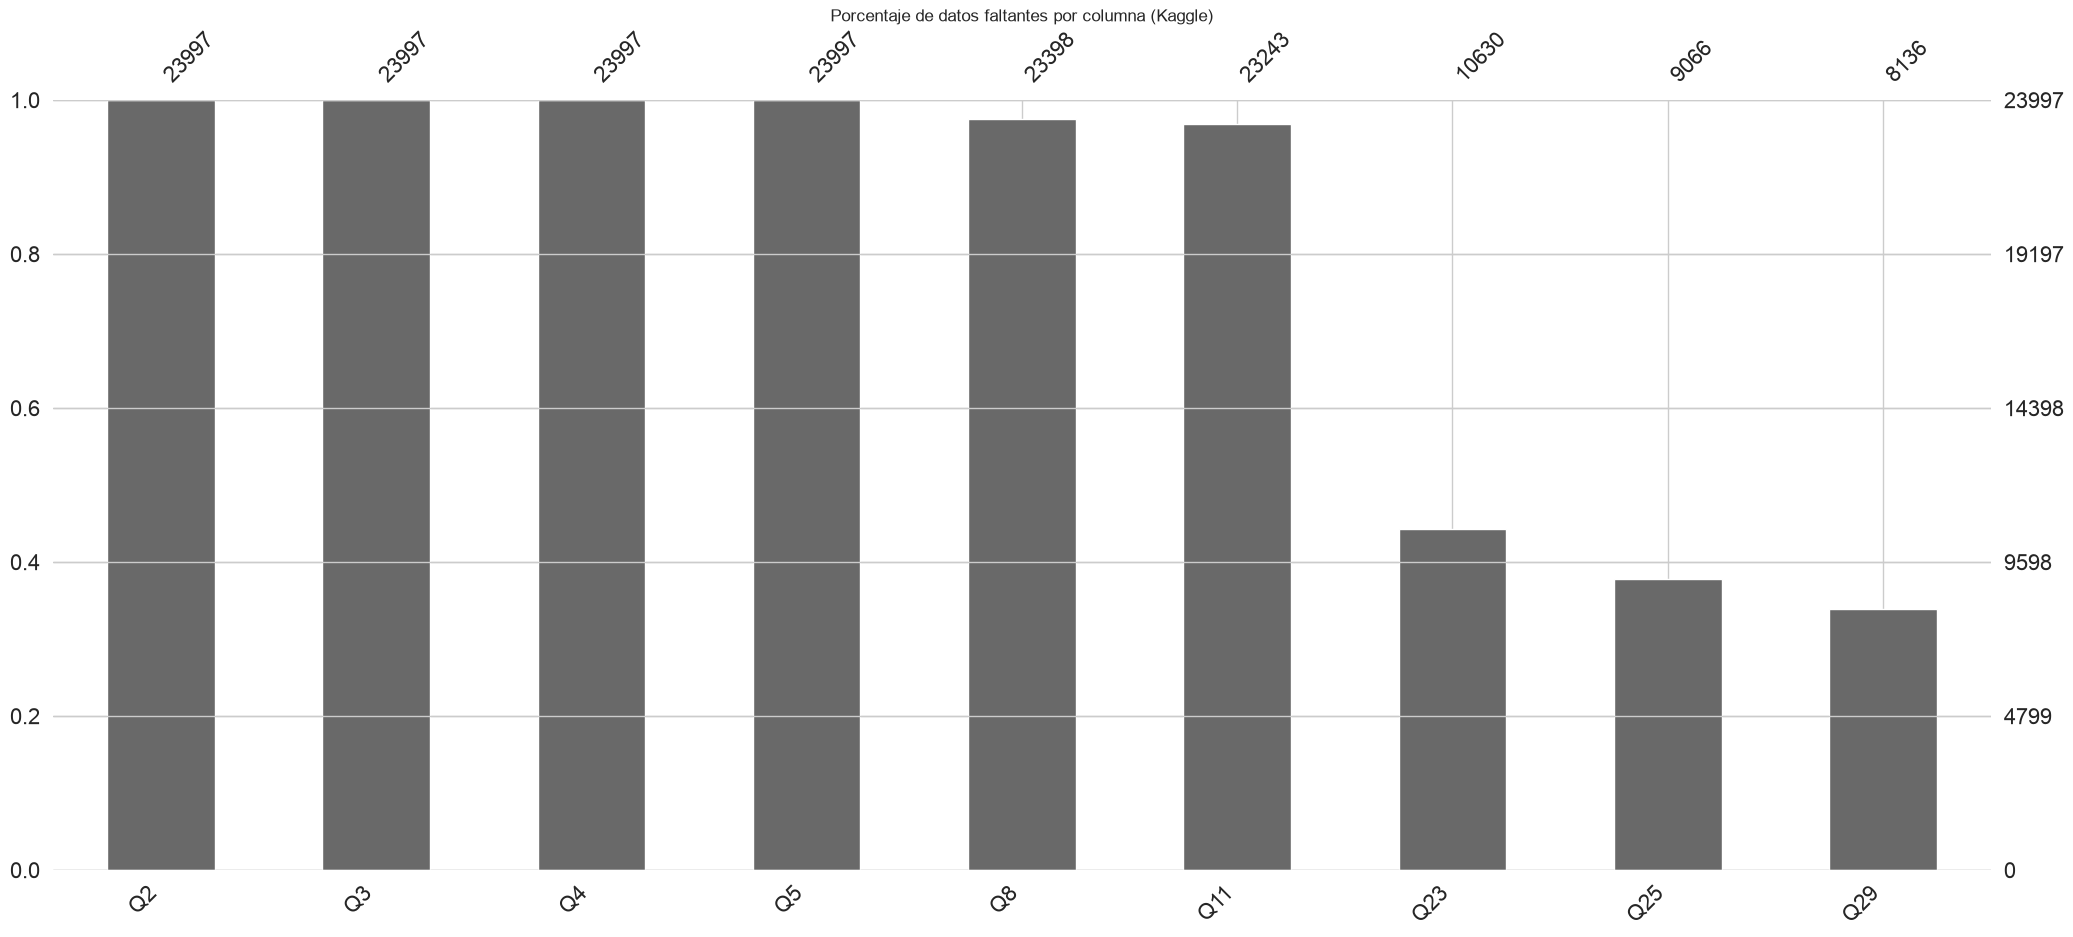

In [10]:
msno.bar(kg[cols_interes])
plt.title("Porcentaje de datos faltantes por columna (Kaggle)")
plt.show()

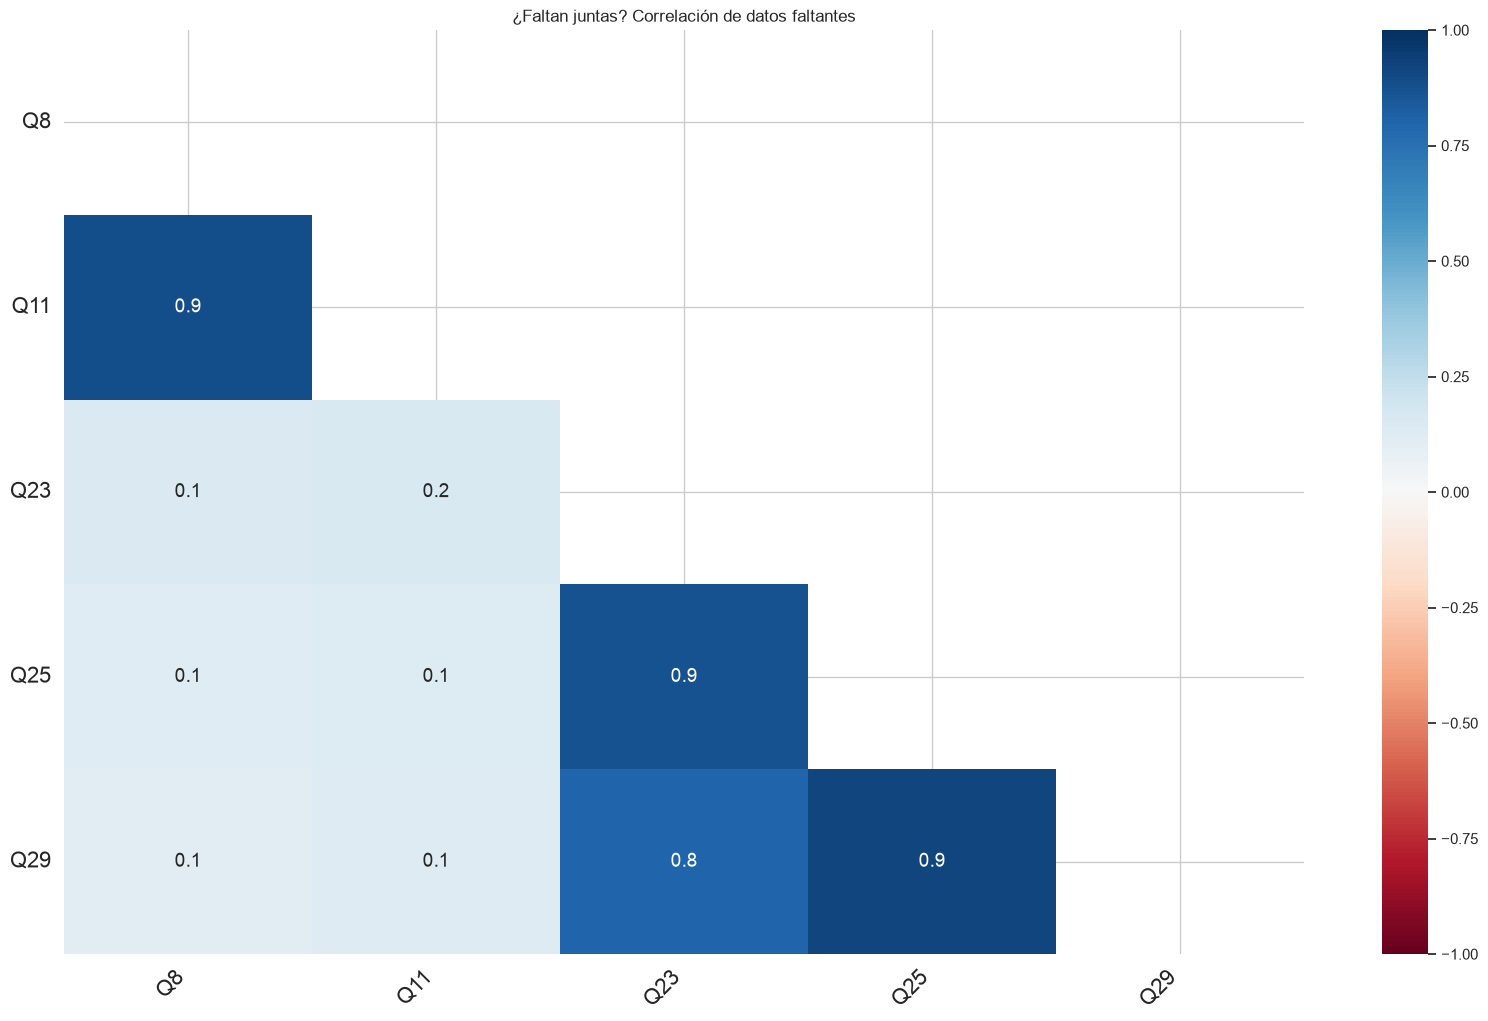

In [11]:
cols_con_nulos = ["Q8", "Q11", "Q23", "Q25", "Q29"]
msno.heatmap(kg[cols_con_nulos])
plt.title("¿Faltan juntas? Correlación de datos faltantes")
plt.show()

Role, company_size y salary faltan a la vez, por lo que son preguntas condicionales del tipo "solo si trabajas"

In [12]:
kg[["Q2", "Q3", "Q4", "Q5", "Q8", "Q11", "Q23", "Q25", "Q29"]].isna().mean().mul(100).round(1)

Q2      0.0
Q3      0.0
Q4      0.0
Q5      0.0
Q8      2.5
Q11     3.1
Q23    55.7
Q25    62.2
Q29    66.1
dtype: float64

## 5. Limpieza (con justificación)

| Decisión | Por qué |
|---|---|
| Pasar Eurostat a formato largo y separar valor/flag | Las celdas mezclan número y letra; así se puede filtrar y graficar |
| Convertir `:` en NaN y **no imputar** | Imputar inventaría datos oficiales; mejor documentar el hueco |
| Filtrar Kaggle a países europeos | Para adaptarlo a la situación real |
| Agrupar género en Hombre / Mujer / Otro | Las categorías minoritarias son demasiado pequeñas para analizarlas por separado |
| NO imputes Q23, Q25 ni Q29. Rellenar "rol" o "salario" con la mediana o moda sería inventar datos de gente que no trabaja. Lo correcto es dejarlas como NaN y filtrarlas solo cuando hagas el análisis concreto de rol/salario. | |

In [13]:
# Eurostat -> formato largo
sex_long = eurostat_to_long(es_sex, id_cols=["freq", "unit", "sex", "geo"])
age_long = eurostat_to_long(es_age, id_cols=["freq", "unit", "age", "geo"])
sex_long.head()

,freq,unit,sex,geo,year,flag,value
0,A,PC,F,AT,2004,be,22.1
1,A,PC,F,BA,2004,<NA>,<NA>
2,A,PC,F,BE,2004,e,15.1
3,A,PC,F,BG,2004,e,26.4
4,A,PC,F,CH,2004,<NA>,<NA>


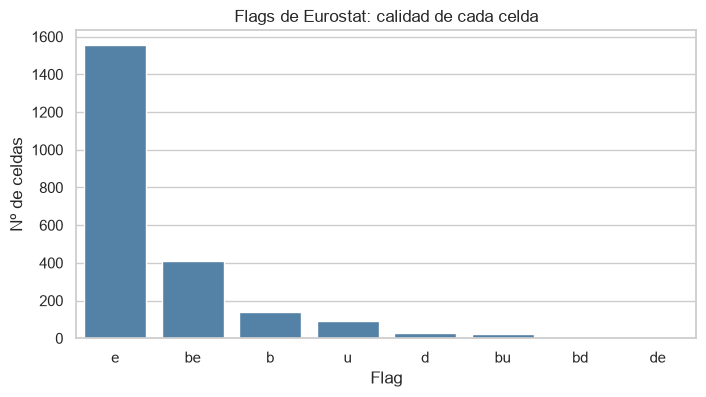

In [14]:
flag_counts = sex_long["flag"].value_counts(dropna=False)
plt.figure(figsize=(8, 4))
sns.barplot(x=flag_counts.index.astype(str), y=flag_counts.values, color="steelblue")
plt.title("Flags de Eurostat: calidad de cada celda")
plt.xlabel("Flag"); plt.ylabel("Nº de celdas")
plt.show()

In [15]:
print("Flags presentes:", sex_long["flag"].value_counts(dropna=False).to_dict())
print("Valores nulos (value):", sex_long["value"].isna().sum())

Flags presentes: {'e': 1556, <NA>: 998, 'be': 408, 'b': 140, 'u': 90, 'd': 30, 'bu': 24, 'bd': 8, 'de': 2}
Valores nulos (value): 370


In [16]:
# Kaggle: renombrar, género y filtro a Europa
kg = kg.drop_duplicates()                                    # ← añade esta línea
kg = kg.rename(columns={v: k for k, v in COLS.items() if v})
kg["gender_clean"] = normalize_gender(kg["gender"])

print(sorted(kg["country"].dropna().unique()))   # revisa los nombres reales
kg_eu = kg[kg["country"].isin(COUNTRY_TO_GEO.keys())].copy()
print(kg_eu.shape)
kg_eu["gender_clean"].value_counts()

['Algeria', 'Argentina', 'Australia', 'Bangladesh', 'Belgium', 'Brazil', 'Cameroon', 'Canada', 'Chile', 'China', 'Colombia', 'Czech Republic', 'Ecuador', 'Egypt', 'Ethiopia', 'France', 'Germany', 'Ghana', 'Hong Kong (S.A.R.)', 'I do not wish to disclose my location', 'India', 'Indonesia', 'Iran, Islamic Republic of...', 'Ireland', 'Israel', 'Italy', 'Japan', 'Kenya', 'Malaysia', 'Mexico', 'Morocco', 'Nepal', 'Netherlands', 'Nigeria', 'Other', 'Pakistan', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'South Korea', 'Spain', 'Sri Lanka', 'Taiwan', 'Thailand', 'Tunisia', 'Turkey', 'Ukraine', 'United Arab Emirates', 'United Kingdom of Great Britain and Northern Ireland', 'United States of America', 'Viet Nam', 'Zimbabwe']
(1569, 297)


gender_clean
Hombre              1269
Mujer                266
Otro / No indica      34
Name: count, dtype: int64

## 6. Nuevas variables (feature engineering)

In [17]:
# 1) Código de país para el merge
kg_eu["geo"] = kg_eu["country"].map(COUNTRY_TO_GEO)

# 2) Junior: define aquí el criterio (ej. menos de 2 años de experiencia)
JUNIOR_VALUES = ["< 1 years", "1-3 years"]   # junior = hasta 3 años programando
kg_eu["is_junior"] = kg_eu["experience"].isin(JUNIOR_VALUES)

# 3) Indicador de mujer
kg_eu["is_woman"] = (kg_eu["gender_clean"] == "Mujer")

# 4) Grupos de edad (la encuesta trae rangos de texto; ajusta si hace falta)
kg_eu["age_group"] = kg_eu["age"]

# Eurostat: periodo antes/después de la ruptura de serie de 2021
sex_long["period"] = np.where(sex_long["year"] >= 2021, "2021+", "pre-2021")
kg_eu[["geo", "is_junior", "is_woman"]].head()

,geo,is_junior,is_woman
3,FR,False,False
7,DE,False,False
19,IT,False,False
33,IT,False,False
48,FR,False,False


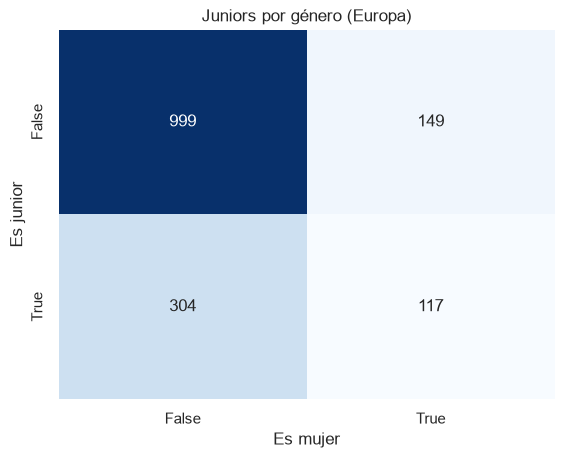

In [18]:
ct = pd.crosstab(kg_eu["is_junior"], kg_eu["is_woman"])
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Juniors por género (Europa)")
plt.xlabel("Es mujer"); plt.ylabel("Es junior")
plt.show()

El número absoluto (117) es pequeño porque la muestra europea es pequeña.
- 7.5% de los encuestados europeos son mujeres junior (117 / 1 569).
- 44% de las mujeres europeas de la encuesta son junior (117 / 266).
- 27.8% de los juniors son mujeres (117 / 421).

## 7. Análisis univariado (mín. 3 variables)

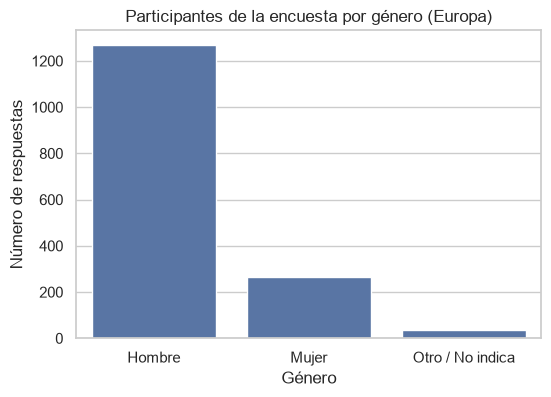

In [19]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=kg_eu, x="gender_clean", ax=ax)
ax.set_title("Participantes de la encuesta por género (Europa)")
ax.set_xlabel("Género"); ax.set_ylabel("Número de respuestas")
plt.show()

**Análisis — género de los participantes (Europa)**

La encuesta en Europa está claramente dominada por hombres: **1 269 hombres (80.9%)**
frente a **266 mujeres (17%)** y 34 "Otro / No indica" (2.2%).

**Conclusión:** las mujeres son una minoría muy marcada entre los encuestados de
tech en Europa (aproximadamente 1 de cada 6). Esto anticipa el tema del análisis:
la infrarrepresentación femenina en el sector.

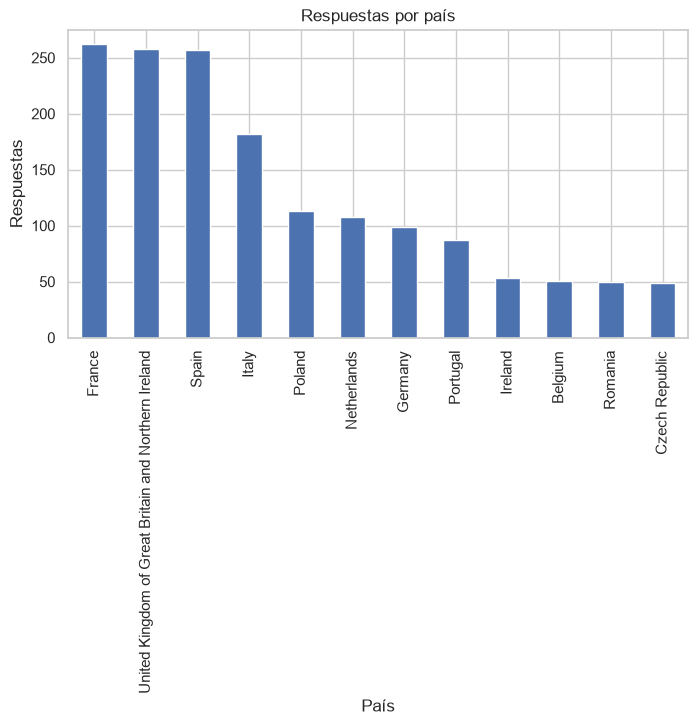

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
kg_eu["country"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Respuestas por país"); ax.set_xlabel("País"); ax.set_ylabel("Respuestas")
plt.show()

**Análisis — respuestas por país (Europa)**

Solo hay **12 países europeos** representados. Los tres con más respuestas están
prácticamente empatados: Francia (262), Reino Unido (258) y España (257). Les siguen
Italia (182) y Polonia (113).

**Conclusión:** la muestra europea se concentra en pocos países (Francia, Reino
Unido y España suman casi la mitad). El resto tienen muestras mucho menores (Chequia,
49). Esto importa al comparar porcentajes por país: en los países pequeños el margen
de error es grande.

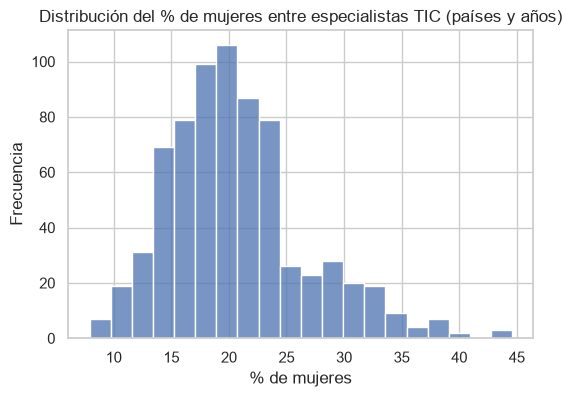

In [21]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(sex_long.query("sex == 'F' and unit == 'PC'")["value"].dropna(), bins=20, ax=ax)
ax.set_title("Distribución del % de mujeres entre especialistas TIC (países y años)")
ax.set_xlabel("% de mujeres"); ax.set_ylabel("Frecuencia")
plt.show()

**Análisis — distribución del % de mujeres entre especialistas TIC**

Considerando todos los países y años con dato (717 observaciones país-año), el % de
mujeres entre especialistas TIC va de **7.9% a 44.6%**, con una media del **20.6%** y
una mediana del 19.6% (la mitad de los casos está entre 16.6% y 23.5%).

**Conclusión:** la distribución se centra en torno al 20%, con una cola hacia la
derecha (algunos países superan el 30-40%). España se mueve en la zona media de su
propio rango histórico (16.5%-23.5%, media 19.9%).

## 8. Análisis bivariado

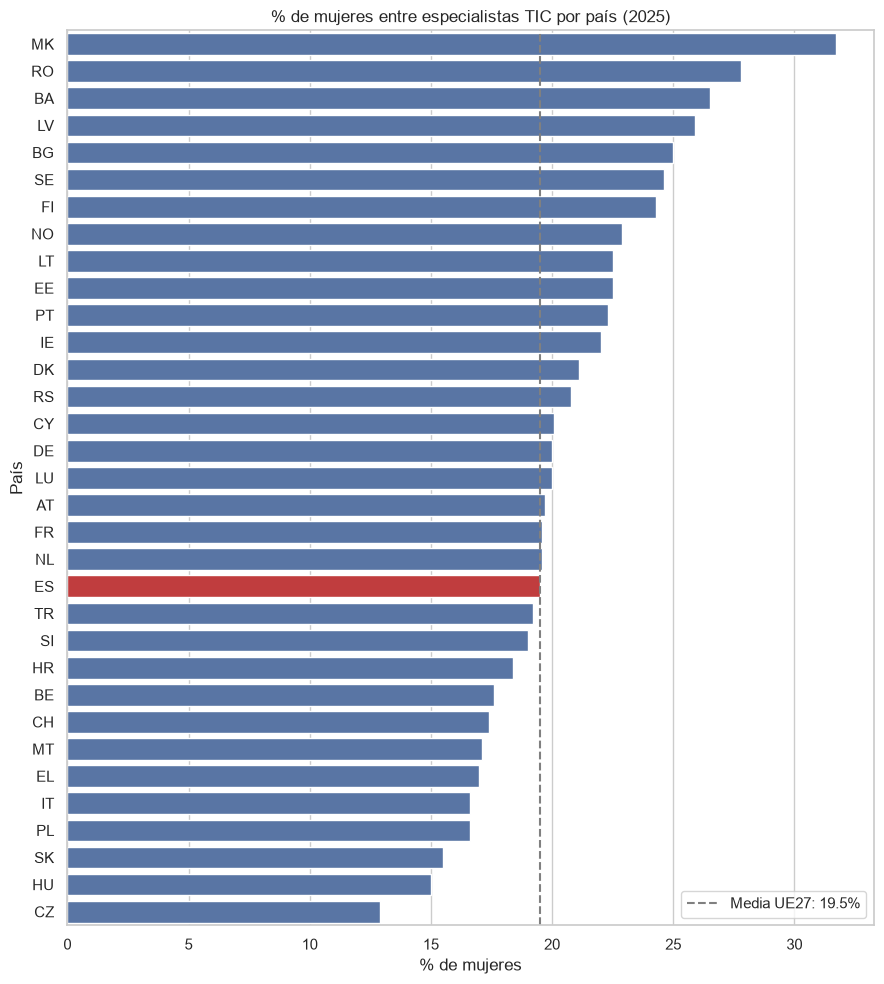

In [22]:
# % de mujeres entre especialistas TIC por país (último año disponible)
last_year = sex_long["year"].max()

df = (sex_long.query("sex == 'F' and unit == 'PC' and year == @last_year")
      .dropna(subset=["value"]))

eu_val = df.loc[df["geo"] == "EU27_2020", "value"]          # media UE como referencia
paises = df[df["geo"] != "EU27_2020"].sort_values("value", ascending=False)

colores = ["#d62728" if g == "ES" else "#4c72b0" for g in paises["geo"]]

fig, ax = plt.subplots(figsize=(9, 10))
sns.barplot(data=paises, y="geo", x="value", hue="geo", palette=colores, legend=False, ax=ax)
if not eu_val.empty:
    ax.axvline(eu_val.iloc[0], color="gray", ls="--", lw=1.5,
               label=f"Media UE27: {eu_val.iloc[0]:.1f}%")
ax.set_title(f"% de mujeres entre especialistas TIC por país ({last_year})")
ax.set_xlabel("% de mujeres")
ax.set_ylabel("País")
ax.legend()
plt.tight_layout()
plt.show()

**Análisis — % de mujeres entre especialistas TIC por país (2025)**

- **España: 19.5%**, prácticamente igual a la media de la UE27 (19.5%).
  Ocupa la posición **21 de 33** países con datos: en la mitad-baja de la tabla.
- Arriba dominan países del este/sudeste de Europa: Macedonia del Norte (31.7%),
  Rumanía (27.8%), Bosnia (26.5%), Letonia (25.9%) y Bulgaria (25.0%).
- Abajo quedan Italia y Polonia (16.6%), Eslovaquia (15.5%), Hungría (15.0%) y
  Chequia (12.9%).

**Conclusión:** España no destaca ni por arriba ni por abajo: se sitúa exactamente
en la media europea. El patrón regional (más mujeres TIC en el este que en el
oeste/centro) sugiere una hipótesis interesante para explorar: la mayor presencia
femenina en carreras técnicas en países con herencia del bloque del este, más que
una cuestión puramente económica.

*Nota: esto mide representación (% de especialistas TIC que son mujeres), no
contratación. Y Eurostat define "especialista TIC" con un criterio concreto de ocupación.*

In [23]:
jun = kg_eu.query("is_junior")
roles_con_muestra = jun["role"].value_counts()[lambda s: s >= 10].index

pd.crosstab(
    jun[jun["role"].isin(roles_con_muestra)]["role"],
    jun[jun["role"].isin(roles_con_muestra)]["gender_clean"],
    normalize="index"
).round(2)

gender_clean,Hombre,Mujer,Otro / No indica
role,,,
Currently not employed,0.77,0.20,0.03
"Data Analyst (Business, Marketing, Financial, Quantitative, etc)",0.69,0.26,0.05
Data Scientist,0.70,0.30,0.00
Engineer (non-software),0.83,0.08,0.08
"Manager (Program, Project, Operations, Executive-level, etc)",0.74,0.26,0.00
Other,0.61,0.39,0.00
Research Scientist,0.79,0.21,0.00


**Análisis — género por rol (solo juniors, Europa)**

Considerando los roles con al menos 10 personas:

- Las mujeres son minoría en **todos** los roles: entre un 8% y un 39%.
- Donde hay más proporción de mujeres: "Other" (39%), Data Scientist (30%),
  Data Analyst (26%) y Manager (26%).
- Donde menos: "Engineer (non-software)", con solo un **8%** de mujeres.

**Conclusión:** entre los juniors europeos, las mujeres se concentran relativamente
más en perfiles de análisis/ciencia de datos y gestión, y están casi ausentes en
ingeniería de software. Aun así, las muestras por rol son pequeñas (10 mujeres en
Data Scientist, 10 en Data Analyst), por lo que estos porcentajes son orientativos.

*Nota: se descartaron los roles con menos de 10 personas (Data Administrator,
Developer Advocate, Software Engineer, Statistician) para no sacar conclusiones
de muestras de 1 o 2 casos.*

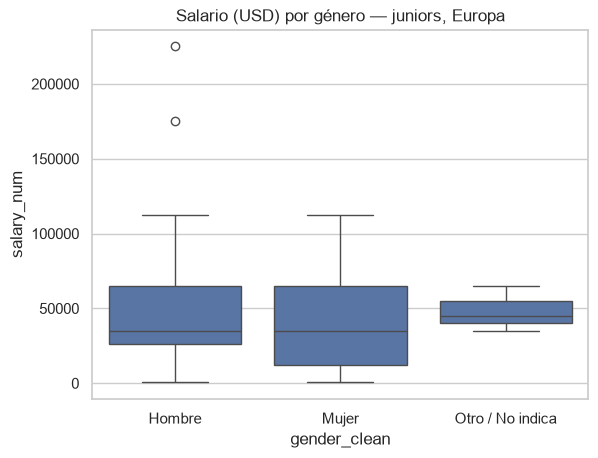

In [24]:
# Salario: pasar de texto (rango) a número (punto medio)
def salario_a_numero(s):
    if pd.isna(s):
        return np.nan
    s = str(s).strip().replace("$", "").replace(",", "")
    if not s:
        return np.nan
    if s.startswith(">"):          # caso ">$1,000,000": usamos el límite inferior
        return float(s[1:].strip())
    if "-" in s:                   # rango "lo-hi" -> punto medio
        lo, hi = s.split("-", 1)
        return (float(lo) + float(hi)) / 2
    return np.nan                  # cualquier otro formato raro

kg_eu["salary_num"] = kg_eu["salary"].apply(salario_a_numero)

sns.boxplot(data=kg_eu.query("is_junior"), x="gender_clean", y="salary_num")
plt.title("Salario (USD) por género — juniors, Europa")
plt.show()

**Análisis — salario por género (solo juniors, Europa)**

Salario anual en USD, estimado por el punto medio del rango declarado:

| Género | n | Mediana | Media |
|---|---|---|---|
| Hombre | 100 | 35 000 | 46 030 |
| Mujer | 39 | 35 000 | 38 083 |
| Otro / No indica | 3 | 45 000 | 48 333 |

- La **mediana es idéntica**: 35 000 USD para hombres y mujeres.
- La **media** sí difiere (46 030 vs 38 083), pero esa diferencia la arrastran
  unos pocos hombres con sueldos muy altos, no el grueso de la distribución.

**Conclusión:** no se aprecia una brecha salarial de mediana entre hombres y
mujeres juniors en Europa. La diferencia en la media no es concluyente porque la
muestra de mujeres con salario es muy pequeña (39 personas) y está dominada por
valores extremos. Para afirmar algo con confianza haría falta mucha más muestra.

*Limitación: 279 de 421 juniors (66%) no declararon salario, y el dato es un
rango autodeclarado, no una cifra exacta.*

## 9. Nivel medio: agrupar, outliers y correlaciones

In [25]:
# groupby + agg
(sex_long.query("sex == 'F' and unit == 'PC'")
 .groupby("geo")["value"].agg(["mean", "min", "max"]).round(1)
 .sort_values("mean", ascending=False).head(10))

,mean,min,max
geo,,,
BG,29.3,25.0,33.0
ME,29.3,27.1,33.0
EE,27.3,19.4,44.1
LV,26.9,20.5,44.1
RO,26.6,21.3,32.3
MK,26.0,22.0,31.7
LT,25.9,17.1,44.6
IE,25.6,18.6,35.7
EL,24.2,14.8,38.3


**Análisis — países con más % de mujeres TIC (media histórica)**

Esta celda agrupa por país y calcula la media, el mínimo y el máximo del % de mujeres
a lo largo de todos los años disponibles.

- Los primeros puestos son del este/sudeste de Europa: Bulgaria (29.3%),
  Montenegro (29.3%), Estonia (27.3%), Letonia (26.9%) y Rumanía (26.6%).
- Las columnas `min`/`max` muestran cuánto fluctúa cada país: Estonia, por ejemplo,
  va de un 19.4% a un 44.1% según el año.

**Conclusión:** se confirma, ahora en media histórica, el patrón del Paso 8: los
países del este lideran, y con bastante variación de un año a otro.

In [26]:
# pivot_table: % mujeres, país x año
pivot = (sex_long.query("sex == 'F' and unit == 'PC'")
         .pivot_table(index="geo", columns="year", values="value"))
pivot.head()

year,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
geo,,,,,,,,,,,,,,,,,,,,,,
AT,22.1,20.0,19.7,20.9,17.6,18.8,19.1,13.2,16.8,14.2,13.4,14.3,17.1,15.7,18.4,20.4,20.3,19.0,19.3,19.5,21.1,19.7
BA,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,17.8,24.3,19.5,20.5,26.5
BE,15.1,18.1,17.3,18.7,17.4,18.4,19.2,16.6,17.1,15.5,15.2,15.1,14.1,15.6,16.8,17.2,17.4,19.6,18.7,19.4,19.0,17.6
BG,26.4,26.5,28.3,28.9,31.3,30.6,31.1,33.0,32.4,29.8,31.6,30.9,29.1,29.2,30.1,28.3,28.4,28.2,28.9,29.1,27.0,25.0
CH,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,12.6,13.3,14.2,13.8,14.2,15.0,15.2,14.5,16.6,16.3,16.4,16.0,16.6,17.9,17.4


**Análisis — tabla pivote (país × año)**

Esta celda reorganiza los datos en una matriz de 37 países (filas) × 22 años
(columnas), donde cada casilla es el % de mujeres de ese país y año.

- Quedan **97 casillas vacías (NaN)**: son los años en los que Eurostat no tiene dato
  (los `:` originales convertidos a nulos en la limpieza).
- Este formato "ancho" es un paso intermedio: permite calcular las correlaciones entre
  años de las celdas siguientes.

**Conclusión:** la tabla en sí no se interpreta; sirve de base para el heatmap de
correlación y para detectar cómo se relacionan los años entre sí.

In [27]:
# Outliers (IQR) del % de mujeres
v = sex_long.query("sex == 'F' and unit == 'PC'")["value"].dropna()
q1, q3 = v.quantile([0.25, 0.75]); iqr = q3 - q1
outliers = v[(v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)]
print(f"{len(outliers)} outliers de {len(v)}")

23 outliers de 717


**Análisis — outliers del % de mujeres TIC (método IQR)**

Con el criterio del rango intercuartílico (Q1 = 16.6%, Q3 = 23.5%, IQR = 6.9), se
considera outlier cualquier valor por encima de **33.8%** (o por debajo de 6.3%).

- Hay **23 outliers de 717** (3.2%), y **todos están por arriba** (ninguno por abajo).
- Son países/años con un % de mujeres inusualmente alto: Estonia (44.1%), Lituania
  (44.6%), etc.

**Conclusión:** los outliers no son errores, sino casos reales de representación
femenina excepcionalmente alta (casi todos del este de Europa). No conviene
eliminarlos; hay que tenerlos presentes al interpretar medias y correlaciones.

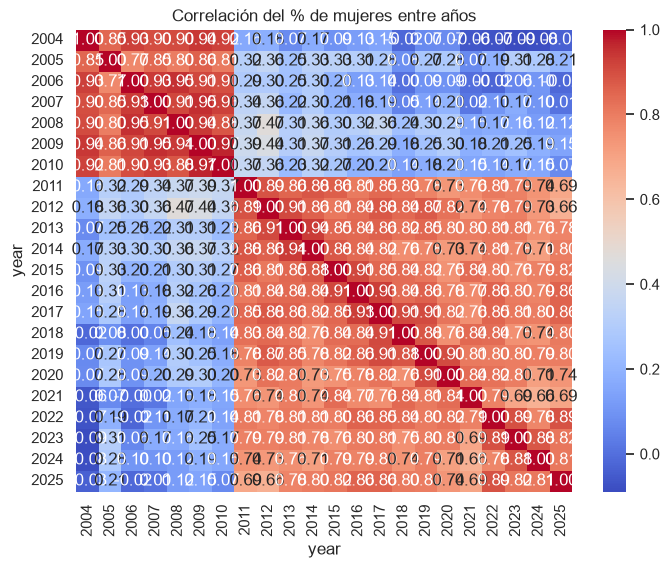

In [28]:
# Matriz de correlación + heatmap (años como columnas)
plt.figure(figsize=(8, 6))
sns.heatmap(pivot.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación del % de mujeres entre años")
plt.show()

**Análisis — correlación del % de mujeres entre años**

El heatmap muestra cuánto se parecen los valores de un año a los del otro (1 = muy
parecidos, -1 = opuestos, 0 = sin relación).

- La diagonal (años consecutivos) es la zona más roja: 2015 vs 2016 correlacionan
  **0.91**, y 2024 vs 2025, **0.81**. Un año se parece mucho al anterior.
- Cuanto más separados están los años, más débil es la relación: 2004 vs 2025
  correlaciona **-0.03** (prácticamente nada).

**Conclusión:** el ranking de países cambia poco de un año a otro, pero a lo largo de
20 años se ha reordenado bastante. La posición de cada país no es fija: ha habido
movimiento real en dos décadas.

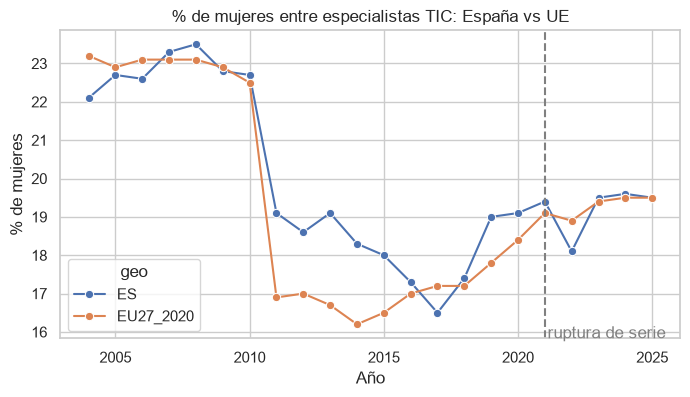

In [29]:
# Tendencia en el tiempo: España vs UE27
trend = sex_long.query("sex == 'F' and unit == 'PC' and geo in ['ES', 'EU27_2020']").dropna(subset=["value"])
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=trend, x="year", y="value", hue="geo", marker="o", ax=ax)
ax.axvline(2021, ls="--", color="gray"); ax.text(2021.1, ax.get_ylim()[0], "ruptura de serie", color="gray")
ax.set_title("% de mujeres entre especialistas TIC: España vs UE"); ax.set_xlabel("Año"); ax.set_ylabel("% de mujeres")
plt.show()

**Análisis — tendencia España vs UE (2004-2025)**

El gráfico compara la evolución de España frente a la media de la UE27.

- España pasa del **22.1% (2004)** al **19.5% (2025)**; la UE27, del **23.2%** al
  **19.5%**. Ambas bajan ligeramente y se mantienen pegadas todo el tiempo.
- La línea gris vertical marca la **ruptura de serie de 2021**: el pequeño salto de ese
  año (España pasa de 19.1% a 19.4%) es un cambio de metodología, no un cambio real.

**Conclusión:** en 20 años, el % de mujeres en tech en España apenas se ha movido
(≈19-22%), siempre en la media europea. Es un estancamiento, no una mejora.

## 10. Nivel avanzado: segunda fuente, normalización e interactividad

In [30]:
# Merge: % de mujeres de la encuesta (por país) + % de mujeres Eurostat (último año)
survey_pct = (kg_eu.groupby("geo")["is_woman"].mean().mul(100).rename("pct_mujeres_encuesta").reset_index())
eurostat_pct = (sex_long.query("sex == 'F' and unit == 'PC' and year == @last_year")[["geo", "value"]]
                .rename(columns={"value": "pct_mujeres_eurostat"}))
merged = survey_pct.merge(eurostat_pct, on="geo", how="inner")
merged

,geo,pct_mujeres_encuesta,pct_mujeres_eurostat
0,BE,5.882353,17.6
1,CZ,20.408163,12.9
2,DE,12.121212,20.0
3,ES,16.342412,19.5
4,FR,16.412214,19.6
5,IE,11.320755,22.0
6,IT,13.736264,16.6
7,NL,16.666667,19.6
8,PL,21.238938,16.6
9,PT,24.137931,22.3


**Análisis — combinando las dos fuentes (merge)**

Esta celda une las dos fuentes en una sola tabla, usando el código de país (`geo`)
como clave:

- `pct_mujeres_encuesta`: % de mujeres en la encuesta de Kaggle (por país).
- `pct_mujeres_eurostat`: % oficial de mujeres entre especialistas TIC (Eurostat, 2025).

El resultado son **12 países** (los que tienen datos en la encuesta). Uno de ellos,
Reino Unido, queda sin dato de Eurostat (UK ya no reporta como país de la UE).

**Conclusión:** este `merge` es el "nivel avanzado" del análisis: contrastar una
fuente oficial (Eurostat) con una muestra autoseleccionada (Kaggle) para comprobar
si la segunda es fiable.

In [31]:
fig = px.scatter(merged, x="pct_mujeres_eurostat", y="pct_mujeres_encuesta", text="geo",
                 title="Encuesta vs Eurostat: % de mujeres por país",
                 labels={"pct_mujeres_eurostat": "% mujeres (Eurostat)", "pct_mujeres_encuesta": "% mujeres (encuesta)"})
fig.show()

**Análisis — ¿coinciden la encuesta y Eurostat?**

Cada punto es un país: el eje X es el % de mujeres según Eurostat y el eje Y, el % de
mujeres según la encuesta. Si coincidieran a la perfección, todos los puntos caerían
sobre la diagonal (y = x).

- La correlación entre ambas fuentes es **moderada (0.42)**: tienden a moverse juntas,
  pero con bastante dispersión.
- La encuesta **sobreestima** en República Checa (20.4% vs 12.9%), Polonia (21.2% vs
  16.6%) y Rumanía (30.0% vs 27.8%).
- La encuesta **subestima** en Bélgica (5.9% vs 17.6%), Alemania (12.1% vs 20.0%) e
  Irlanda (11.3% vs 22.0%).
- España queda cerca: **16.3% (encuesta) vs 19.5% (Eurostat)**.

**Conclusión:** las dos fuentes coinciden en lo esencial (las mujeres son minoría,
≈13-30%), pero la encuesta diverge de los datos oficiales, sobre todo en países con
pocas respuestas (Bélgica, Irlanda, Chequia). La encuesta sirve como aproximación,
pero no es representativa.

**Calidad dudosa a documentar:** ruptura de serie 2021, flags `u`/`b`, tamaño de muestra pequeño en algunos países de la encuesta, sesgo de selección.

## 11. Respuestas a las preguntas

1. **España vs UE y evolución desde 2004:** España está en el **19.5%** (2025), clavada
   en la media de la UE27 (19.5%), en el puesto **21 de 33** países. Desde 2004 ha bajado
   ligeramente (22.1% → 19.5%), igual que la UE (23.2% → 19.5%). En resumen: estancada en
   la media europea durante 20 años.

2. **Plantillas jóvenes y % de mujeres (por país):** la correlación entre el % de plantilla
   joven (Y15-34) y el % de mujeres es **débil y positiva** (0.28 en 2025; 0.24 en media
   histórica). Algunos países con plantilla joven sí tienen más mujeres (Macedonia del Norte,
   Bosnia, Letonia, Lituania), pero otros no (Malta, con 55% de jóvenes, tiene solo un 17% de
   mujeres). La relación existe, pero es débil y con excepciones.

3. **% de mujeres entre juniors (Kaggle):** en Europa hay 1 569 encuestados, de los que
   **266 son mujeres (17%)**. Entre los juniors (≤3 años programando), el **28% son mujeres**
   (117 de 421), por encima del 17% general. Esto sugiere que la presencia femenina es algo
   mayor en las cohortes más recientes.

4. **Formación, rol y salario junior:** en **formación** no hay grandes diferencias (hombres
   y mujeres juniors tienen niveles similares, sobre todo Bachelor's y Master's, con ~30% de
   mujeres). En **rol**, las mujeres se concentran en datos/análisis y gestión (Data Scientist
   30%, Data Analyst 26%, Manager 26%) y están casi ausentes en ingeniería de software (8%).
   En **salario**, la mediana es idéntica (35 000 USD), aunque la media es menor para mujeres
   (38 083 vs 46 030) por unos pocos sueldos muy altos masculinos y la muestra pequeña
   (39 mujeres).

5. **Encuesta vs Eurostat por país:** correlación **moderada (0.42)**. La encuesta sobreestima
   en Chequia (20.4% vs 12.9%) y Polonia (21.2% vs 16.6%), y subestima en Bélgica (5.9% vs
   17.6%) y Alemania (12.1% vs 20.0%). España queda cerca (16.3% vs 19.5%). La encuesta es
   coherente a grandes rasgos, pero no representativa.

## 12. Conclusiones y limitaciones

- **Hallazgo principal (para el CEO):** en España solo ~2 de cada 10 especialistas TIC son
  mujeres (19.5%), un nivel estancado en la media europea desde hace 20 años. La encuesta
  confirma la infrarrepresentación (17% de mujeres) y que apenas hay mujeres junior en
  ingeniería de software (8%).

- **Limitaciones:**
  - Representación ≠ contratación: los datos miden quién trabaja ya, no quién se contrata.
  - Sesgo de selección: la encuesta de Kaggle es autoseleccionada y Europa es solo el 6.5%.
  - Muestra pequeña en salario y rol (39 mujeres junior con salario).
  - Ruptura de serie 2021 y flags `u`/`b`/`e` en Eurostat.
  - "Junior" depende de la categoría "1-3 years"; la encuesta no permite afinar a 2 años.

- **Siguientes pasos:**
  - Conseguir datos de contratación (ofertas y candidatas) para medir la brecha de entrada real.
  - Cruzar edad y sexo para estudiar la "tubería rota" (si las mujeres abandonan el sector).
  - Ampliar la muestra europea de la encuesta para reducir el margen de error.
  - Estudiar por qué los países del este tienen más mujeres en tech, para extraer lecciones.

In [46]:
# Guardar datos limpios
sex_long.to_csv(PROCESSED + "eurostat_sexo_long.csv", index=False)
kg_eu.to_csv(PROCESSED + "kaggle_europa_limpio.csv", index=False)